In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles

n0 : number of entry

n1 : number of neuron in the layer 1

n2 : number of neuron in the layer 2 (here it is the output)

In [3]:
def initialisation(n0, n1, n2) :

    W1 = np.random.randn(n1, n0)
    b1 = np.random.randn(n1, 1)
    W2 = np.random.randn(n2, n1)
    b2 = np.random.randn(n2, 1)

    parameters = {
        'W1' : W1,
        'b1' : b1,
        'W2' : W2,
        'b2' : b2
    }
    return parameters

In [4]:
def forward_propagation(X,parameters) :

    W1 = parameters['W1']
    b1 = parameters['b1']
    W2 = parameters['W2']
    b2 = parameters['b2']

    Z1 = W1.dot(X) + b1
    A1 = 1 / (1 + np.exp(-Z1))

    Z2 = W2.dot(A1) + b2
    A2 = 1 / (1 + np.exp(-Z2))

    activations = {
        'A1' : A1,
        'A2' : A2
    }
    return activations

In [5]:
def log_loss(y, A) :
    
    eps = 1e-15
    A = np.clip(A, eps, 1 - eps)    #clipping : force A compris entre eps et 1-eps pour éviter log(0)
    return -1 / len(y) * np.sum(y * np.log(A) + (1-y) * np.log(1-A))

In [6]:
def back_propagation(X, y, parameters, activations) : 

    m = y.shape[1]
    W2 = parameters['W2']
    A1 = activations['A1']
    A2 = activations['A2']
    
    dZ2 = A2 - y
    dZ1 = W2.T.dot(dZ2) * A1 * (1 - A1)

    dW2 = dZ2.dot(A1.T) / m
    db2 = np.sum(dZ2, axis=1, keepdims=True) / m
    dW1 = dZ1.dot(X.T) / m
    db1 = np.sum(dZ1, axis=1,keepdims=True) / m
# keepdims allows to avoid broadcasting on db (and b when update is called)
# by keeping it in column
    gradients = {
        'dW1' : dW1,
        'db1' : db1,
        'dW2' : dW2,
        'db2' : db2
    }
    return gradients

In [7]:
def update(parameters, gradients, lr) :

    W1 = parameters['W1']
    b1 = parameters['b1']
    W2 = parameters['W2']
    b2 = parameters['b2']

    dW1 = gradients['dW1']
    db1 = gradients['db1']
    dW2 = gradients['dW2']
    db2 = gradients['db2']

    W1 = W1 - lr * dW1
    b1 = b1 - lr * db1
    W2 = W2 - lr * dW2
    b2 = b2 - lr * db2

    parameters = {
        'W1' : W1,
        'b1' : b1,
        'W2' : W2,
        'b2' : b2
    }
    return parameters

In [8]:
def predict(X, parameters) :
    activations = forward_propagation(X, parameters)
    A2 = activations['A2']
    return A2 >= 0.5

In [9]:
from sklearn.metrics import accuracy_score
from tqdm import tqdm

In [10]:
def neural_network(X_train, y_train, n1=2, lr = 0.1, n_iter = 100):
    
    n0 = X_train.shape[0]
    n2 = y_train.shape[0]

    parameters = initialisation(n0, n1, n2)

    train_loss = []
    train_acc = []

    for i in tqdm(range(n_iter)):
        activations = forward_propagation(X_train, parameters)
        gradients = back_propagation(X_train, y_train, parameters, activations)
        parameters = update(parameters, gradients, lr)
        
        if i %10 == 0:
            train_loss.append(log_loss(y_train, activations['A2']))
            y_pred = predict(X_train, parameters)
            train_acc.append(accuracy_score(y_train.flatten(), y_pred.flatten()))




    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(train_loss, label='train loss')
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(train_acc, label='train acc')
    plt.legend()
    plt.show()

    return (parameters)

(2, 100) (1, 100)


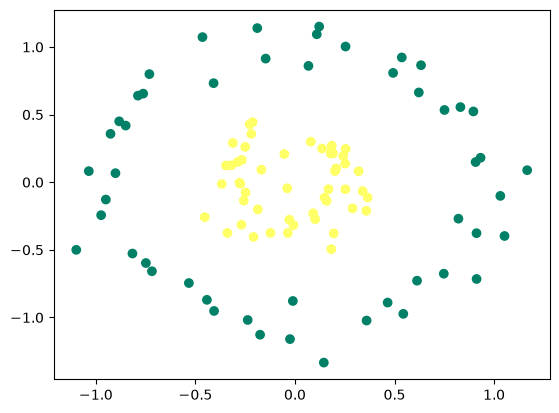

In [11]:
X, y = make_circles(n_samples=100, noise=0.1, factor=0.3, random_state=0)

#convention 2 : column version
X = X.T 
y = y.reshape(1, y.shape[0])
print(X.shape, y.shape)

plt.scatter(X[0,:], X[1,:], c=y, cmap='summer')
plt.show()

100%|██████████| 10000/10000 [00:01<00:00, 7316.19it/s]


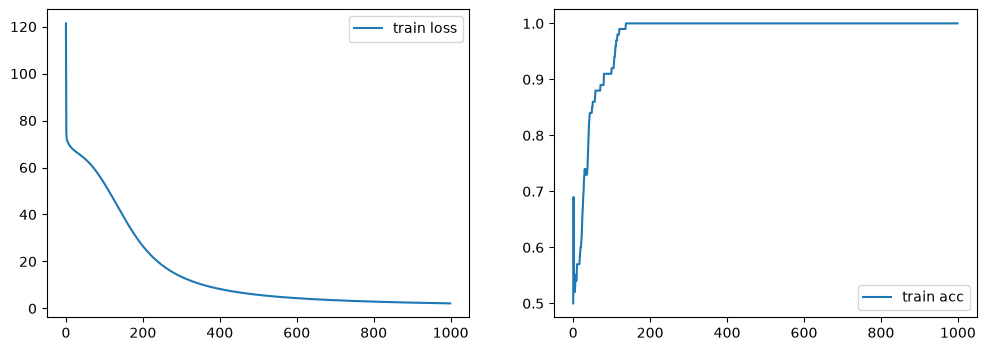

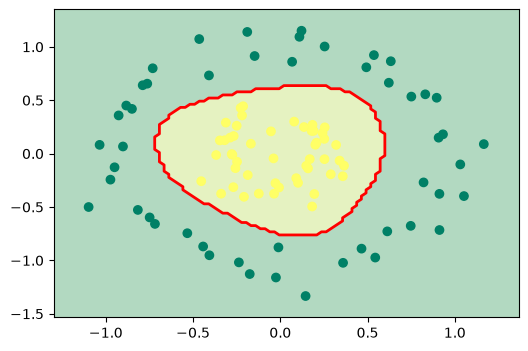

In [15]:
parameters = neural_network(X, y, n1=16, lr=0.1, n_iter=10000)

W1 = parameters['W1']
b1 = parameters['b1']
W2 = parameters['W2']
b2 = parameters['b2']

x_min, x_max = X[0, :].min() - 0.2, X[0, :].max() + 0.2
y_min, y_max = X[1, :].min() - 0.2, X[1, :].max() + 0.2
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                     np.linspace(y_min, y_max, 100))
grid = np.c_[xx.ravel(), yy.ravel()].T

Z1 = W1.dot(grid) + b1
A1 = 1 / (1 + np.exp(-Z1))
Z2 = W2.dot(A1) + b2
A2 = 1 / (1 + np.exp(-Z2))

Z = (A2 >= 0.5).reshape(xx.shape)

plt.figure(figsize=(6, 4))
plt.contourf(xx, yy, Z, cmap='summer', alpha=0.4)              
plt.contour(xx, yy, Z, levels=[0.5], colors='red', linewidths=2) 
plt.scatter(X[0, :], X[1, :], c=y.flatten(), cmap='summer')    
plt.show()